In [1]:
import numpy as np
import heapq
import time
import matplotlib.pyplot as plt
import pandas as pd
from heuristics import manhattan_distance, euclidean_distance, chebyshev_distance
from astar import astar

grid = np.loadtxt("results/grid.csv", delimiter=",", dtype=int)
start = tuple(np.loadtxt("results/start.csv", delimiter=",", dtype=int))
goal = tuple(np.loadtxt("results/goal.csv", delimiter=",", dtype=int))

In [2]:
heuristics = {
    "Manhattan": manhattan_distance,
    "Euclidean": euclidean_distance,
    "Chebyshev": chebyshev_distance
}

In [ ]:
def visualize_path(grid, start, goal, path, title="A* Path"):

    rows, cols = grid.shape
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(grid, cmap="Greys", vmin=0, vmax=1)

    if path is not None:
        path_rows = [p[0] for p in path]
        path_cols = [p[1] for p in path]

        ax.plot(
            path_cols,
            path_rows,
            color="blue",
            linewidth=2.5,
            marker="o",
            markersize=4,
            label="Path"
        )

    ax.scatter(
        start[1], start[0],
        color="green", s=250, marker="o",
        edgecolors="black", label="Start", zorder=3
    )

    ax.scatter(
        goal[1], goal[0],
        color="red", s=250, marker="*",
        edgecolors="black", label="Goal", zorder=3
    )

    ax.set_xticks(np.arange(-0.5, cols, 1))
    ax.set_yticks(np.arange(-0.5, rows, 1))

    ax.grid(color="black", linewidth=0.5)

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_title(title)
    ax.legend(loc="upper right")

    plt.show()


Manhattan Heuristic
------------------------------
Success: True
Path length: 4
Nodes expanded: 5
Execution time: 0.0003220000071451068
Maximum frontier size: 7


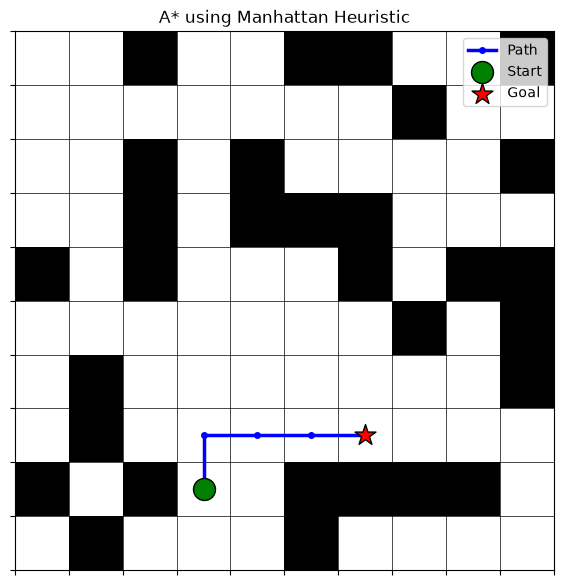


Euclidean Heuristic
------------------------------
Success: True
Path length: 4
Nodes expanded: 5
Execution time: 0.0021986999781802297
Maximum frontier size: 7


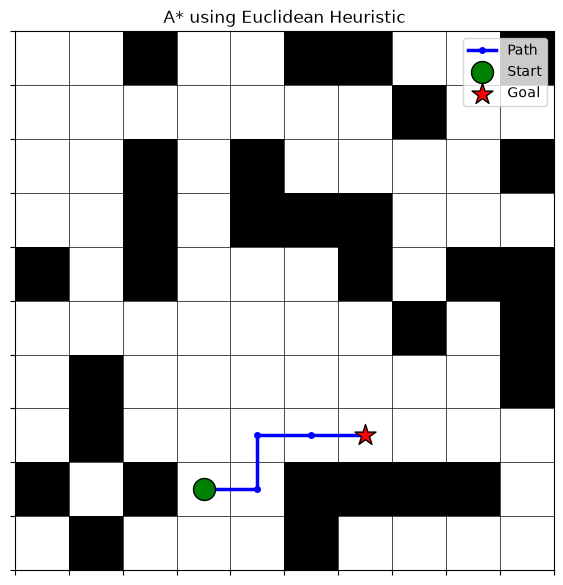


Chebyshev Heuristic
------------------------------
Success: True
Path length: 4
Nodes expanded: 7
Execution time: 7.290003122761846e-05
Maximum frontier size: 6


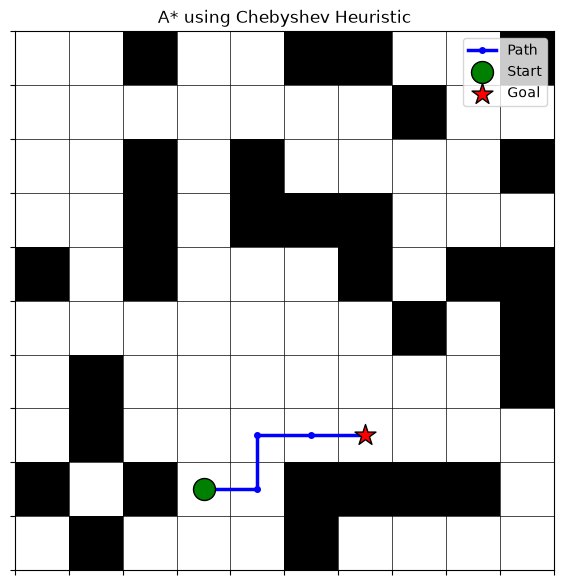

In [4]:
results = {}

for name, heuristic in heuristics.items():

    result = astar(grid, start, goal, heuristic)

    results[name] = result

    print(f"\n{name} Heuristic")
    print("-" * 30)
    print("Success:", result["success"])
    print("Path length:", result["path_length"])
    print("Nodes expanded:", result["nodes_expanded"])
    print("Execution time:", result["execution_time"])
    print("Maximum frontier size:", result["max_frontier_size"])

    if result["success"]:
        visualize_path(
            grid,
            start,
            goal,
            result["path"],
            title=f"A* using {name} Heuristic"
        )

In [5]:
comparison = pd.DataFrame([
    {
        "Heuristic": name,
        "Success": result["success"],
        "Path Length": result["path_length"],
        "Nodes Expanded": result["nodes_expanded"],
        "Execution Time (ms)": result["execution_time"] * 1000,
        "Max Frontier Size": result["max_frontier_size"]
    }
    for name, result in results.items()
])

comparison

,Heuristic,Success,Path Length,Nodes Expanded,Execution Time (ms),Max Frontier Size
0,Manhattan,True,4,5,0.3220,7
1,Euclidean,True,4,5,2.1987,7
2,Chebyshev,True,4,7,0.0729,6
